## Inference for Proportions and A/B Testing
---

## Experiment: simulate a Bernoulli conversion experiment and verify the standard error.

In [1]:
import numpy as np

rng = np.random.default_rng(188)
p, n, repetitions = 0.20, 400, 20_000
counts = rng.binomial(n, p, size=repetitions)
phats = counts / n

print(f"Mean estimated conversion: {phats.mean():.4f} (true {p:.4f})")
print(f"Simulated SD of estimates: {phats.std(ddof=1):.5f}")
print(f"Theoretical SE:           {np.sqrt(p * (1-p) / n):.5f}")

Mean estimated conversion: 0.2000 (true 0.2000)
Simulated SD of estimates: 0.01997
Theoretical SE:           0.02000


## Experiment: compare Wald, Wilson, and exact intervals at every possible count.

For 2/12:
Wald  : [-0.0442, 0.3775]
Wilson: [0.0470, 0.4480]
Exact : [0.0209, 0.4841]


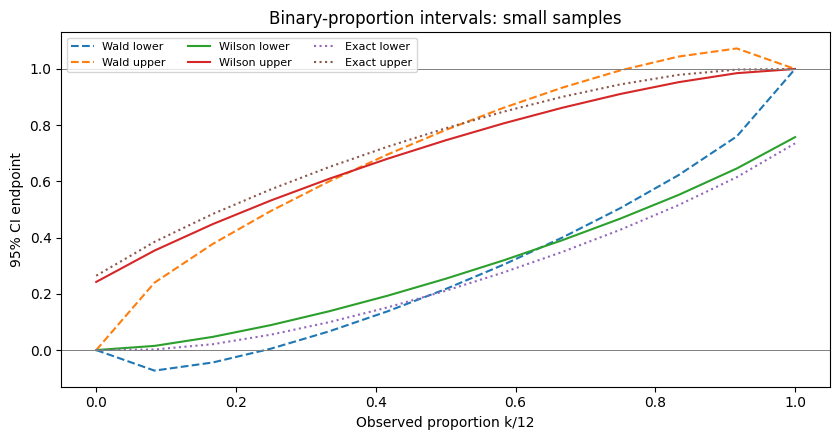

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binomtest
from statsmodels.stats.proportion import proportion_confint

n = 12
k = np.arange(n + 1)
phat = k / n
z = norm.ppf(0.975)
wald_low = phat - z * np.sqrt(phat * (1-phat) / n)
wald_high = phat + z * np.sqrt(phat * (1-phat) / n)
wilson = np.array([proportion_confint(int(x), n, alpha=0.05,
                                     method="wilson") for x in k])
exact = np.array([binomtest(int(x), n).proportion_ci(method="exact")
                  for x in k], dtype=float)

print("For 2/12:")
for name, low, high in [("Wald", wald_low[2], wald_high[2]),
                        ("Wilson", *wilson[2]), ("Exact", *exact[2])]:
    print(f"{name:6s}: [{low:.4f}, {high:.4f}]")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(phat, wald_low, "--", label="Wald lower")
ax.plot(phat, wald_high, "--", label="Wald upper")
ax.plot(phat, wilson[:, 0], label="Wilson lower")
ax.plot(phat, wilson[:, 1], label="Wilson upper")
ax.plot(phat, exact[:, 0], ":", label="Exact lower")
ax.plot(phat, exact[:, 1], ":", label="Exact upper")
ax.axhline(0, color="gray", lw=0.7)
ax.axhline(1, color="gray", lw=0.7)
ax.set(xlabel="Observed proportion k/12", ylabel="95% CI endpoint",
       title="Binary-proportion intervals: small samples")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig("../../images/ab_single_proportion_intervals.png", dpi=160)
plt.show()

## Experiment: calculate an exact binomial p-value by hand and with SciPy.

In [3]:
from math import comb
from scipy.stats import binomtest, norm

n, k, p0 = 12, 10, 0.5
upper = sum(comb(n, j) * p0**j * (1-p0)**(n-j)
            for j in range(k, n+1))
manual_p = 2 * upper  # Valid here because p0 = 1/2 is symmetric.
result = binomtest(k, n, p=p0, alternative="two-sided")
zhat = (k/n - p0) / ((p0*(1-p0)/n)**0.5)
print(f"Exact p:  {manual_p:.8f} (SciPy: {result.pvalue:.8f})")
print(f"Normal score approximation p: {2*norm.sf(abs(zhat)):.8f}")
print(f"95% Wilson CI: {result.proportion_ci(method='wilson')}")

Exact p:  0.03857422 (SciPy: 0.03857422)
Normal score approximation p: 0.02092134
95% Wilson CI: ConfidenceInterval(low=0.5519691377470266, high=0.953034857816146)


## Experiment: reproduce the pooled two-proportion z-test and effect measures.

In [4]:
import numpy as np
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest

xA, nA = 80, 400
xB, nB = 110, 400
pA, pB = xA / nA, xB / nB
pooled = (xA + xB) / (nA + nB)
se0 = np.sqrt(pooled * (1-pooled) * (1/nA + 1/nB))
z = (pB-pA) / se0
pvalue = 2 * norm.sf(abs(z))
sm_z, sm_p = proportions_ztest([xB, xA], [nB, nA])
print(f"Risk difference:     {pB-pA:.4f} ({100*(pB-pA):.2f} pp)")
print(f"Risk ratio:          {pB/pA:.3f} ({100*(pB/pA-1):.1f}% relative uplift)")
print(f"Pooled z: {z:.4f}; two-sided p: {pvalue:.6f}")
print(f"statsmodels: z={sm_z:.4f}; p={sm_p:.6f}")


Risk difference:     0.0750 (7.50 pp)
Risk ratio:          1.375 (37.5% relative uplift)
Pooled z: 2.4924; two-sided p: 0.012687
statsmodels: z=2.4924; p=0.012687


## Experiment: compare Wald and Newcombe confidence intervals for absolute uplift.

Wald difference CI:    (0.01625214336490754, 0.13374785663509248)
Newcombe difference CI: (0.016003857359308864, 0.13337220067818994)


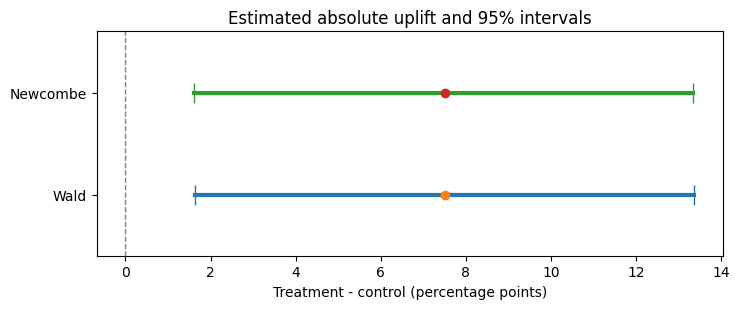

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.stats.proportion import confint_proportions_2indep

xA, nA, xB, nB = 80, 400, 110, 400
pA, pB = xA/nA, xB/nB
uplift = pB-pA
se = np.sqrt(pA*(1-pA)/nA + pB*(1-pB)/nB)
wald = (uplift - norm.ppf(.975)*se, uplift + norm.ppf(.975)*se)
newcombe = confint_proportions_2indep(xB, nB, xA, nA,
                                     compare="diff", method="newcomb")
print(f"Wald difference CI:    {wald}")
print(f"Newcombe difference CI: {newcombe}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for i, (name, (lo, hi)) in enumerate([("Wald", wald),
                                      ("Newcombe", newcombe)]):
    ax.plot([100*lo, 100*hi], [i, i], marker="|", lw=3, markersize=15)
    ax.plot(100*uplift, i, marker="o")
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set(yticks=[0, 1], yticklabels=["Wald", "Newcombe"],
       xlabel="Treatment - control (percentage points)",
       title="Estimated absolute uplift and 95% intervals")
ax.set_ylim(-0.6, 1.6)
fig.tight_layout()
fig.savefig("../../images/ab_uplift_intervals.png", dpi=160)
plt.show()

## Experiment: use Fisher exact testing when the contingency table is sparse.

In [6]:
from scipy.stats import fisher_exact, chi2_contingency

# Rows are groups; columns are failures and non-failures.
table = [[1, 11], [6, 6]]
odds_ratio, p_fisher = fisher_exact(table, alternative="two-sided")
chi2, p_chi2, *_ = chi2_contingency(table, correction=False)
print(f"Fisher conditional odds ratio: {odds_ratio:.4f}")
print(f"Fisher exact two-sided p:      {p_fisher:.6f}")
print(f"Chi-square approximation p:   {p_chi2:.6f}")

Fisher conditional odds ratio: 0.0909
Fisher exact two-sided p:      0.068650
Chi-square approximation p:   0.024740


## Experiment: simulate many A/A experiments and inspect false-positive calibration.

In [7]:
import numpy as np
from scipy.stats import norm

rng = np.random.default_rng(194)
trials, n, p = 5000, 500, 0.15
xA = rng.binomial(n, p, size=trials)
xB = rng.binomial(n, p, size=trials)
pool = (xA+xB)/(2*n)
se0 = np.sqrt(pool*(1-pool)*(2/n))
z = np.divide(xB/n-xA/n, se0, out=np.zeros(trials), where=se0>0)
pvalues = 2 * norm.sf(abs(z))
print(f"A/A rejection fraction at alpha=.05: {np.mean(pvalues<.05):.3f}")
print("Expected Monte Carlo SE near 0.05:",
      round(np.sqrt(.05*.95/trials), 4))

A/A rejection fraction at alpha=.05: 0.056
Expected Monte Carlo SE near 0.05: 0.0031


## Experiment: calculate power and approximate sample size for a planned uplift.

Approximate n/arm:  3841
Arcsine n/arm:      3835


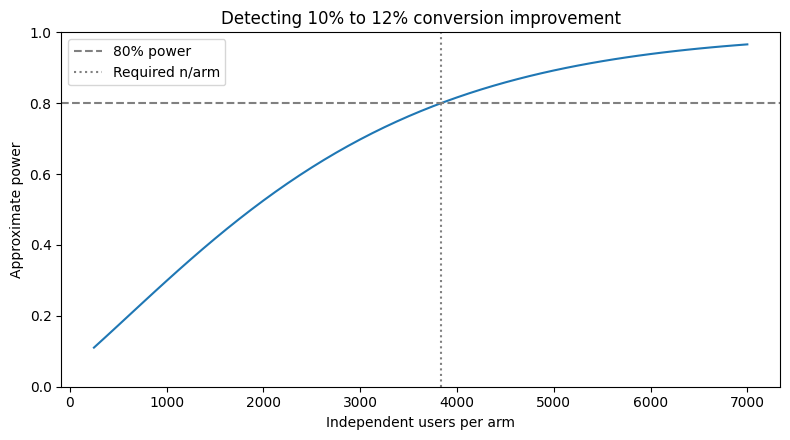

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower

pA, pB, alpha, target_power = .10, .12, .05, .80
pbar = (pA+pB)/2
delta = pB-pA
approx_n = ((norm.ppf(1-alpha/2)*np.sqrt(2*pbar*(1-pbar))
             +norm.ppf(target_power)*np.sqrt(pA*(1-pA)+pB*(1-pB)))
            /delta)**2
h = abs(proportion_effectsize(pA, pB))
model = NormalIndPower()
arcsine_n = model.solve_power(effect_size=h, power=target_power,
                              alpha=alpha, alternative="two-sided")
print(f"Approximate n/arm:  {np.ceil(approx_n):.0f}")
print(f"Arcsine n/arm:      {np.ceil(arcsine_n):.0f}")

sizes = np.arange(250, 7001, 125)
powers = model.power(effect_size=h, nobs1=sizes, ratio=1,
                     alpha=alpha, alternative="two-sided")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, powers)
ax.axhline(.8, color="gray", ls="--", label="80% power")
ax.axvline(np.ceil(arcsine_n), color="gray", ls=":", label="Required n/arm")
ax.set(xlabel="Independent users per arm", ylabel="Approximate power",
       ylim=(0, 1), title="Detecting 10% to 12% conversion improvement")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/ab_power_sample_size.png", dpi=160)
plt.show()

## Experiment: simulate repeated significance peeking under a true null.

False positives at final look: 0.051
False positives if stopped at any look: 0.150


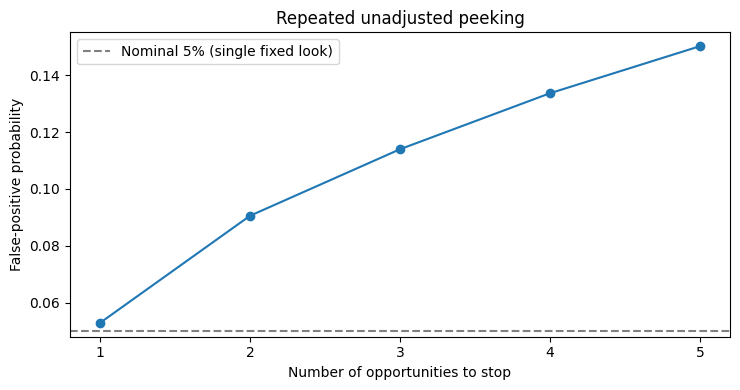

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(196)
trials, looks, users_per_look, p = 3500, 5, 200, .15
# Independent new users enter in each look; the same users remain in later looks.
A = rng.binomial(users_per_look, p, size=(trials, looks))
B = rng.binomial(users_per_look, p, size=(trials, looks))
xA, xB = A.cumsum(axis=1), B.cumsum(axis=1)
n = users_per_look * np.arange(1, looks+1)[None, :]
pool = (xA+xB)/(2*n)
se = np.sqrt(pool*(1-pool)*2/n)
z = np.divide(xB/n-xA/n, se, out=np.zeros_like(pool, dtype=float),
              where=se>0)
pvals = 2 * norm.sf(abs(z))
false_alarm = np.any(pvals < .05, axis=1)
print(f"False positives at final look: {np.mean(pvals[:, -1]<.05):.3f}")
print(f"False positives if stopped at any look: {false_alarm.mean():.3f}")

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.plot(np.arange(1, looks+1),
        [np.mean(np.any(pvals[:, :k]<.05, axis=1))
         for k in range(1, looks+1)], marker="o")
ax.axhline(.05, ls="--", color="gray", label="Nominal 5% (single fixed look)")
ax.set(xlabel="Number of opportunities to stop", ylabel="False-positive probability",
       xticks=np.arange(1, looks+1), title="Repeated unadjusted peeking")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/ab_optional_stopping.png", dpi=160)
plt.show()

## Experiment: control multiplicity with Holm and Benjamini–Hochberg.

In [10]:
import numpy as np
from statsmodels.stats.multitest import multipletests

metrics = ["Primary conversion", "Retention", "Signup", "Complaint rate"]
pvalues = np.array([.009, .021, .040, .20])
for method in ["holm", "fdr_bh"]:
    reject, adjusted, _, _ = multipletests(pvalues, alpha=.05,
                                         method=method)
    print(method)
    for name, raw, adj, decision in zip(metrics, pvalues, adjusted, reject):
        print(f"  {name:21s} raw={raw:.3f}, adjusted={adj:.3f}, reject={decision}")

holm
  Primary conversion    raw=0.009, adjusted=0.036, reject=True
  Retention             raw=0.021, adjusted=0.063, reject=False
  Signup                raw=0.040, adjusted=0.080, reject=False
  Complaint rate        raw=0.200, adjusted=0.200, reject=False
fdr_bh
  Primary conversion    raw=0.009, adjusted=0.036, reject=True
  Retention             raw=0.021, adjusted=0.042, reject=True
  Signup                raw=0.040, adjusted=0.053, reject=False
  Complaint rate        raw=0.200, adjusted=0.200, reject=False


## Experiment: detect sample-ratio mismatch using the exact binomial test.

In [11]:
from scipy.stats import binomtest

n_control, n_treatment = 4800, 5200
n_total = n_control+n_treatment
result = binomtest(n_treatment, n_total, p=.5, alternative="two-sided")
print(f"Observed treatment share: {n_treatment/n_total:.4f}")
print(f"Expected treatment share: .5000")
print(f"Exact SRM p-value:         {result.pvalue:.8f}")
print("Investigate logging, randomization, and analysis eligibility first.")

Observed treatment share: 0.5200
Expected treatment share: .5000
Exact SRM p-value:         0.00006594
Investigate logging, randomization, and analysis eligibility first.


## Experiment: simulate how treating repeated sessions as independent inflates false positives.

In [12]:
import numpy as np
from scipy.stats import norm, ttest_ind

rng = np.random.default_rng(199)
trials, users, sessions = 1500, 180, 8
# Under the null, both arms have identically distributed user propensities.
# Strong within-user correlation comes from heterogeneous propensities.
propensity = rng.beta(.5, 1.5, size=(trials, 2, users, 1))
successes = rng.binomial(1, propensity, size=(trials, 2, users, sessions))

# INCORRECT: consider every session an independent Bernoulli observation.
session_rate = successes.mean(axis=(2, 3))
pooled = successes.sum(axis=(1, 2, 3)) / (2*users*sessions)
naive_se = np.sqrt(pooled*(1-pooled)*2/(users*sessions))
naive_z = np.divide(session_rate[:, 1]-session_rate[:, 0], naive_se,
                    out=np.zeros(trials), where=naive_se>0)
naive_p = 2*norm.sf(abs(naive_z))

# CORRECT FOR THIS DESIGN: independent users, each summarized by a rate.
user_rates = successes.mean(axis=3)
proper_p = ttest_ind(user_rates[:, 1, :], user_rates[:, 0, :],
                     axis=1, equal_var=False).pvalue
print(f"Session-naive false-positive rate: {(naive_p<.05).mean():.3f}")
print(f"User-level false-positive rate:    {(proper_p<.05).mean():.3f}")

Session-naive false-positive rate: 0.265
User-level false-positive rate:    0.049
